# Libraries

In [1]:
import sys
sys.path.insert(0, '..')
from pythons_for_plugin.single_traj_prediction import *

from andi_datasets.datasets_challenge import challenge_theory_dataset
import torch
from pathlib import Path
import torch.nn as nn
from step.models import XResAttn
from fastai.vision.all import Learner, DataLoaders, MSELossFlat, L
import time
from torch.nn import L1Loss
from tqdm.auto import tqdm

from matplotlib import pyplot as plt

dvc = 'cuda' if torch.cuda.is_available() else 'cpu'

/home/gorka/github/andi_datasets/andi_datasets/utils_videos.py:22: UserWarning: From your imports it seems that you will need Deeptrack. Install if needed using pip install deeptrack.
  warnings.warn('From your imports it seems that you will need Deeptrack. Install if needed using pip install deeptrack.')


# EXP 8

In [12]:
backbone_single = XResAttn(2, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
    block_szs=[128, 256, 512], dropout=0., pos_enc=False, n_encoder_layers=4,
    dim_ff=512, nhead_enc=8, norm=False, linear_layers=[])

model_single = SingleTrajModel(backbone_single).to('cuda')

model_single.load_state_dict(torch.load("models/kistep_adapted_single_exp8.pth"))
model_single.eval();

  0%|          | 0/5 [00:00<?, ?it/s]

attm (avg=0.383): {0.1: 0.84, 0.31: 0.38, 0.52: 0.23, 0.73: 0.22, 0.94: 0.25}
ctrw (avg=0.172): {0.1: 0.24, 0.31: 0.12, 0.52: 0.16, 0.73: 0.15, 0.94: 0.19}
fbm (avg=0.294): {0.1: 0.54, 0.31: 0.85, 0.52: 0.57, 0.73: 0.25, 0.94: 0.18, 1.15: 0.16, 1.36: 0.14, 1.57: 0.12, 1.78: 0.08, 1.99: 0.04}
lw (avg=0.195): {1.15: 0.24, 1.36: 0.16, 1.57: 0.15, 1.78: 0.2, 1.99: 0.22}
sbm (avg=0.263): {0.1: 0.49, 0.31: 0.36, 0.52: 0.26, 0.73: 0.24, 0.94: 0.2, 1.15: 0.2, 1.36: 0.18, 1.57: 0.25, 1.78: 0.21, 1.99: 0.24}
[0.3831258130633831, 0.1721197566628456, 0.2937308406180143, 0.1945501169967651, 0.2632708804404736]


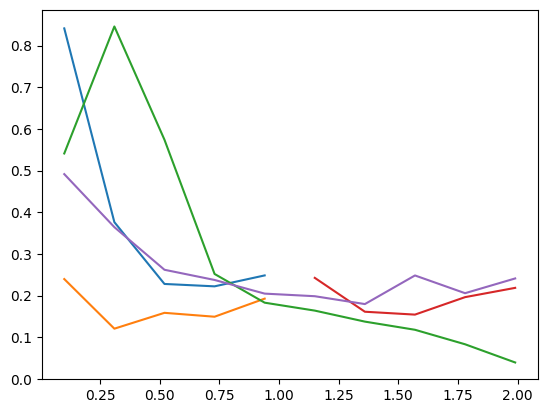

In [48]:
from andi_datasets.datasets_theory import datasets_theory
from andi_datasets.utils_trajectories import normalize

DT = datasets_theory()

T = 50; N = 100
models = np.arange(5)
models_alpha = ['sub', 'sub', 'all', 'super', 'all']

mae = []

num_exponents = 10
mse_exponent = np.zeros((len(models), num_exponents))
BATCH_SIZE = 512  # run inference in chunks to avoid GPU OOM
all_exponents = np.linspace(0.1, 1.99, num_exponents)
for idxm, model in enumerate(tqdm(models)):
    if models_alpha[model] == 'sub':
        idx_exps = np.where(all_exponents <= 1)[0]
        exponents = all_exponents[idx_exps]
    elif models_alpha[model] == 'super':
        idx_exps = np.where(all_exponents >= 1)[0]
        exponents = all_exponents[idx_exps]
    elif models_alpha[model] == 'all':
        idx_exps = np.arange(num_exponents)
        exponents = all_exponents[idx_exps]

    # if idxm == 0:
    #     continue

    dataset = DT.create_dataset(T = T, N_models = N, exponents = exponents.tolist(), models = [model], dimension = 2)

    n_traj = dataset.shape[0]
    norm_trajs = normalize(dataset[:, 2:].reshape(n_traj*2, T)).reshape(dataset[:, 2:].shape)
    dataset[:, 2:] = norm_trajs.reshape(dataset[:, 2:].shape)

    inputs = dataset[:, 2:].reshape(-1, 2, T).transpose(0,2,1)
    inputs += np.random.randn(*inputs.shape) * 0.01
    polar_np = cartesian_to_relative_polar(inputs)  # keep on CPU

    # Batched inference to avoid GPU OOM
    n = len(polar_np)
    pred_list = []
    model_single.eval()
    with torch.no_grad():
        for start in range(0, n, BATCH_SIZE):
            chunk = torch.tensor(polar_np[start:start+BATCH_SIZE], dtype=torch.float).to(dvc)
            pred_list.append(model_single(chunk).cpu().numpy().flatten())
            del chunk
    pred = np.concatenate(pred_list)

    maes = np.abs(pred - dataset[:, 1])

    mae.append(float(np.mean(maes)))

    mse_exponent[idxm, idx_exps] = maes.reshape(len(idx_exps), N).mean(1)

    # print(DT.avail_models_name[idxm], 'exps:', exponents)
    # # print(pred.reshape(len(idx_exps), N).mean(1).round(2))
    # print(mse_exponent[idxm, idx_exps] .round(2))
    avg = round(float(mse_exponent[idxm, idx_exps].mean()), 3)
    result = {round(e, 2): round(v, 2) for e, v in zip(exponents, mse_exponent[idxm, idx_exps])}
    print(f"{DT.avail_models_name[idxm]} (avg={avg}): {result}")

    plt.plot(exponents, maes.reshape(len(idx_exps), N).mean(1), label = DT.avail_models_name[idxm])

print(mae)


In [35]:
X1, Y1, X2, Y2, X3, Y3 = challenge_theory_dataset(N = 5000, tasks = 1, dimensions = 2,
                                            min_T = 10, max_T = 200, load_dataset = False)

# Prepare data in polar representation
inputs = X1[1]
outputs = torch.tensor(Y1[1]).to(dvc)

tensor_X = []
for i in inputs:
    traj = torch.tensor(i).reshape(2, -1).T.unsqueeze(0) # This gives a tensor of shape (1, T, 2) for each trajectory, where T is the length of the trajectory. 
    tensor_X.append(traj)
lengths = [t.shape[1] for t in tensor_X]
polar_X = [torch.tensor(cartesian_to_relative_polar(traj), dtype=torch.float).to(dvc) for traj in tensor_X]


Creating a dataset for task(s) 1 and dimension(s) 2.
Generating dataset for dimension 2.


In [36]:

preds = []
for traj in polar_X:
    pred = model_single(traj)
    preds.append(pred)
preds = torch.cat(preds).flatten()

In [50]:
num_exponents = 10
exponents = np.linspace(0, 1.99, num_exponents)
mae_exp = np.zeros(num_exponents-1)
for exp in range(1, num_exponents):
    idx = torch.where((exponents[exp-1] < outputs) & (outputs <= exponents[exp]))
    mae_exp[exp-1] = (preds[idx]-outputs[idx]).abs().mean()


In [ ]:
exponen

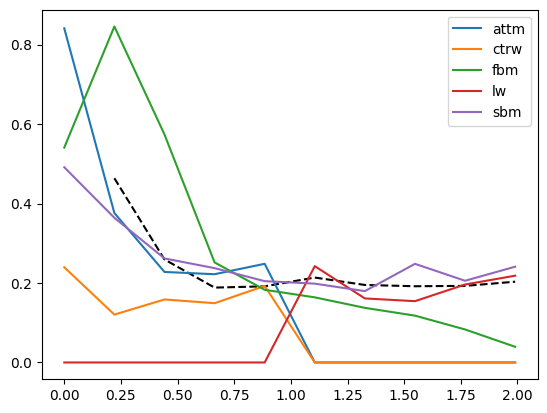

In [51]:
plt.plot(exponents[1:], mae_exp, c = 'k', ls = '--')
plt.plot(exponents, mse_exponent.T, label = DT.avail_models_name)
plt.legend()

### Benchmarking againts just STEP output avg

In [3]:
# STEPalpha: Anomalous exponent model
model_kistep = XResAttn(2, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
             block_szs=[128, 256, 512], dropout=0., pos_enc=False, n_encoder_layers=4,
             dim_ff=512, nhead_enc=8, norm=False, linear_layers=[],yrange=(-0.1,2.1)).to('cuda')

model_kistep.load_state_dict(torch.load('../model_weights/xresattn_alpha_2d_varlen_relpolar_yrange_m01_21_big22E2.pth')['model'])
model_kistep.eval();


In [10]:
pred.mean().cpu()

tensor(0.8542)

In [27]:
preds_step = []
for traj in tqdm(polar_X):
    with torch.no_grad():
        pred = model_kistep(traj).median().cpu()
    preds_step.append(pred)
preds_step = torch.stack(preds_step).flatten()

  0%|          | 0/5000 [00:00<?, ?it/s]

In [28]:
num_exponents = 20
exponents = np.linspace(0, 1.99, num_exponents)
mae_exp_step = np.zeros(num_exponents-1)
for exp in range(1, num_exponents):
    idx = torch.where((exponents[exp-1] < outputs.cpu()) & (outputs.cpu() <= exponents[exp]))
    mae_exp_step[exp-1] = (preds_step[idx]-outputs.cpu()[idx]).abs().mean()


In [29]:
mae_exp.mean(), mae_exp_step.mean()

(0.23046318837095772, 0.4316948136597551)

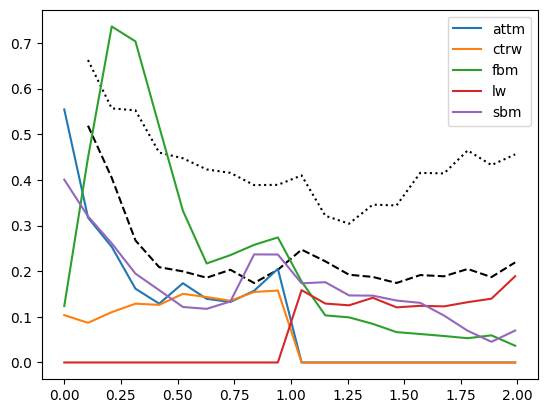

In [30]:
plt.plot(exponents[1:], mae_exp, c = 'k', ls = '--')
plt.plot(exponents[1:], mae_exp_step, c = 'k', ls = ':')
plt.plot(exponents, mse_exponent.T, label = DT.avail_models_name)
plt.legend()